# Grafos no dirigidos

**Matemática Discreta (2026/27)** · Edgar Martínez-Moro · Departamento de Matemática Aplicada, Escuela de Ingeniería Informática, Universidad de Valladolid

Este cuaderno acompaña a la sesión 14 del tema de **teoría de grafos**. Contiene:

1. Representación de un grafo: lista de aristas y matriz de adyacencia.
2. Grados y el lema de los apretones de manos.
3. Potencias de la matriz y trayectorias.
4. Componentes conexas (recorrido en anchura).
5. Grafos simples, isomorfismo e invariantes.
6. Grafos no etiquetados.

## Repaso

Un grafo $G=(V,A)$ tiene un conjunto de vértices $V$ y un conjunto de aristas $A$; cada arista une dos vértices, no necesariamente distintos. Un **lazo** une un vértice consigo mismo, y dos aristas con los mismos extremos son **múltiples**. Un grafo **simple** no tiene ni lazos ni aristas múltiples.

En este cuaderno un grafo es un par `(vertices, aristas)`: una lista de vértices y una lista de pares. Las aristas múltiples se escriben repetidas y un lazo es un par `(x, x)`.

Para dibujar los grafos usamos una función sencilla con `matplotlib`: las posiciones de los vértices se dan a mano.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch



def dibujar(pos, aristas, dirigido=False, pesos=None, resaltar=(), titulo=None,
            tam=(4, 3), radio=0.22):
    """
    pos: {vértice: (x, y)}; aristas: lista de pares (o de ternas con peso).
    Las aristas repetidas se dibujan curvadas; los lazos, como un pequeño círculo.
    resaltar: aristas que se pintan en rojo.
    """
    fig, ax = plt.subplots(figsize=tam)
    resaltar = {frozenset(a[:2]) for a in resaltar} if not dirigido else {tuple(a[:2]) for a in resaltar}
    vistas, total = {}, {}
    for a in aristas:
        clave = (a[0], a[1]) if dirigido else frozenset((a[0], a[1]))
        total[clave] = total.get(clave, 0) + 1
    for a in aristas:
        x, y = a[0], a[1]
        if not dirigido and str(x) > str(y):
            x, y = y, x                      # mismo sentido para curvar las múltiples
        w = a[2] if len(a) > 2 else None
        clave = (x, y) if dirigido else frozenset((x, y))
        k = vistas.get(clave, 0)
        vistas[clave] = k + 1
        rojo = (clave in resaltar)
        color = "darkred" if rojo else "teal"
        lw = 2.4 if rojo else 1.4
        if x == y:
            cx, cy = pos[x]
            ax.add_patch(plt.Circle((cx, cy - radio * 1.2), radio * 0.9, fill=False, color=color, lw=lw))
            continue
        t = total[clave]
        curva = 0.3 * (k - (t - 1) / 2) if t > 1 else 0.0
        if dirigido and (y, x) in [tuple(b[:2]) for b in aristas]:
            curva = 0.2
        flecha = FancyArrowPatch(pos[x], pos[y], connectionstyle=f"arc3,rad={curva}",
                                 arrowstyle="-|>" if dirigido else "-", mutation_scale=14,
                                 color=color, lw=lw, shrinkA=9, shrinkB=9)
        ax.add_patch(flecha)
        if w is not None or (pesos and clave in pesos):
            w = w if w is not None else pesos[clave]
            (x1, y1), (x2, y2) = pos[x], pos[y]
            ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(w), fontsize=8, ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
    for v, (x, y) in pos.items():
        ax.text(x, y, str(v), ha="center", va="center", fontsize=9, zorder=3,
                bbox=dict(boxstyle="circle,pad=0.3", fc="#e6f2f2", ec="teal"))
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 0.6, max(xs) + 0.6)
    ax.set_ylim(min(ys) - 0.6, max(ys) + 0.6)
    ax.set_aspect("equal")
    ax.set_axis_off()
    if titulo:
        ax.set_title(titulo, fontsize=10)
    fig.tight_layout()
    plt.show()
    return fig

In [2]:
from collections import deque
from itertools import combinations, permutations
from math import comb

## 1. Matriz de adyacencia y grados

$m_{ij}$ es el número de aristas que unen $x_i$ y $x_j$ (un lazo cuenta una vez en $m_{ii}$). El grado de $x$ es el número de aristas que inciden en él, contando dos veces cada lazo.

In [3]:
def matriz_adyacencia(vertices, aristas):
    """m_ij = número de aristas entre x_i y x_j (un lazo cuenta 1 en m_ii)."""
    pos = {x: i for i, x in enumerate(vertices)}
    n = len(vertices)
    M = [[0] * n for _ in range(n)]
    for x, y in aristas:
        i, j = pos[x], pos[y]
        M[i][j] += 1
        if i != j:
            M[j][i] += 1
    return M


def grado(x, aristas):
    """Aristas que inciden en x; cada lazo cuenta dos veces."""
    return sum((a == x) + (b == x) for a, b in aristas)


def grados(vertices, aristas):
    return {x: grado(x, aristas) for x in vertices}


def grados_desde_matriz(M):
    """gr(x_i) = suma de la fila i + m_ii."""
    return [sum(M[i]) + M[i][i] for i in range(len(M))]


def mostrar_matriz(M, etiquetas=None):
    n = len(M)
    etiquetas = etiquetas or [str(i + 1) for i in range(n)]
    ancho = max(max(len(str(x)) for fila in M for x in fila), max(map(len, map(str, etiquetas))))
    print(" " * (ancho + 1) + " ".join(str(e).rjust(ancho) for e in etiquetas))
    for e, fila in zip(etiquetas, M):
        print(str(e).rjust(ancho) + " " + " ".join(str(x).rjust(ancho) for x in fila))

El ejemplo de las transparencias: dos aristas entre $x_1$ y $x_2$, un triángulo, una arista $\{x_4,x_5\}$ y un lazo en $x_5$.

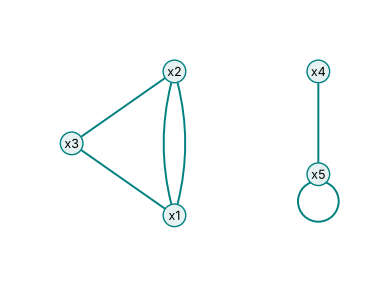

In [4]:
V = ["x1", "x2", "x3", "x4", "x5"]
A = [("x1", "x2"), ("x1", "x2"), ("x1", "x3"), ("x2", "x3"), ("x4", "x5"), ("x5", "x5")]
pos = {"x1": (1, 0), "x2": (1, 1.4), "x3": (0, 0.7), "x4": (2.4, 1.4), "x5": (2.4, 0.4)}
dibujar(pos, A);

In [5]:
M = matriz_adyacencia(V, A)
mostrar_matriz(M, V)
print()
print("grados:", grados(V, A))
print("desde la matriz:", grados_desde_matriz(M))
print("suma de grados =", sum(grados(V, A).values()), "= 2 x", len(A))

   x1 x2 x3 x4 x5
x1  0  2  1  0  0
x2  2  0  1  0  0
x3  1  1  0  0  0
x4  0  0  0  0  1
x5  0  0  0  1  1

grados: {'x1': 3, 'x2': 3, 'x3': 2, 'x4': 1, 'x5': 3}
desde la matriz: [3, 3, 2, 1, 3]
suma de grados = 12 = 2 x 6


**Lema de los apretones de manos.** La suma de los grados es $2|A|$, porque cada arista se cuenta en sus dos extremos. En consecuencia, el número de vértices de grado impar es par (aquí, $x_1$, $x_2$, $x_4$ y $x_5$).

### Königsberg

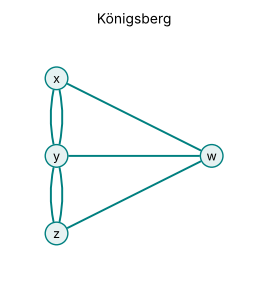

{'x': 3, 'y': 5, 'z': 3, 'w': 3}


In [6]:
K = ["x", "y", "z", "w"]
KA = [("x", "y"), ("x", "y"), ("y", "z"), ("y", "z"), ("x", "w"), ("y", "w"), ("z", "w")]
dibujar({"x": (0, 2), "y": (0, 1), "z": (0, 0), "w": (2, 1)}, KA, titulo="Königsberg")
print(grados(K, KA))

## 2. Trayectorias

La entrada $(i,j)$ de $M^k$ es el número de trayectorias de longitud $k$ de $x_i$ a $x_j$. Para **describirlas**, y no sólo contarlas, las generamos por vuelta atrás; las aristas se numeran para distinguir las múltiples.

In [7]:
def producto(A, B):
    """Producto de matrices de enteros."""
    Bt = list(zip(*B))
    return [[sum(a * b for a, b in zip(f, c)) for c in Bt] for f in A]


def potencia(M, k):
    R = M
    for _ in range(k - 1):
        R = producto(R, M)
    return R


def trayectorias(vertices, aristas, x, y, k):
    """
    Lista de trayectorias de longitud k de x a y. Cada una es una lista
    alternada de vértices y números de arista (las aristas múltiples se
    distinguen por su número).
    """
    incidentes = {v: [] for v in vertices}
    for num, (a, b) in enumerate(aristas, 1):
        incidentes[a].append((num, b))
        if a != b:
            incidentes[b].append((num, a))
    resultado = []

    def seguir(v, camino, quedan):
        if quedan == 0:
            if v == y:
                resultado.append(list(camino))
            return
        for num, w in incidentes[v]:
            camino += [num, w]
            seguir(w, camino, quedan - 1)
            del camino[-2:]

    seguir(x, [x], k)
    return resultado


def fmt_trayectoria(t, nombres_aristas=None):
    partes = []
    for i, e in enumerate(t):
        if i % 2 == 0:
            partes.append(str(e))
        else:
            partes.append(f"-{nombres_aristas[e] if nombres_aristas else 'a' + str(e)}-")
    return "".join(partes)

In [8]:
mostrar_matriz(potencia(M, 3), V)
T = trayectorias(V, A, "x1", "x3", 3)
print()
print(len(T), "trayectorias de longitud 3 de x1 a x3:")
for t in T:
    print("  ", fmt_trayectoria(t))

   x1 x2 x3 x4 x5
x1  4 12  6  0  0
x2 12  4  6  0  0
x3  6  6  4  0  0
x4  0  0  0  1  2
x5  0  0  0  2  3

6 trayectorias de longitud 3 de x1 a x3:
   x1-a1-x2-a1-x1-a3-x3
   x1-a1-x2-a2-x1-a3-x3
   x1-a2-x2-a1-x1-a3-x3
   x1-a2-x2-a2-x1-a3-x3
   x1-a3-x3-a3-x1-a3-x3
   x1-a3-x3-a4-x2-a4-x3


$a_1, a_2$ son las dos aristas entre $x_1$ y $x_2$; $a_3=\{x_1,x_3\}$ y $a_4=\{x_2,x_3\}$.

### Problema 4.13

$M$ es la matriz de un grafo con vértices $x_1,\dots,x_6$.

In [9]:
M13 = [[0, 1, 1, 0, 0, 1],
       [1, 0, 1, 0, 0, 1],
       [1, 1, 0, 1, 1, 0],
       [0, 0, 1, 0, 0, 1],
       [0, 0, 1, 0, 0, 1],
       [1, 1, 0, 1, 1, 0]]
V13 = [f"x{i}" for i in range(1, 7)]
A13 = [(V13[i], V13[j]) for i in range(6) for j in range(i + 1, 6) if M13[i][j]]
print("grados:", dict(zip(V13, grados_desde_matriz(M13))))
M2 = potencia(M13, 2)
print("trayectorias de longitud 2 de x2 a x3:", M2[1][2])
T = [t for t in trayectorias(V13, A13, "x2", "x6", 3) if "x3" in t]
print("trayectorias de longitud 3 de x2 a x6 que pasan por x3:", len(T))
for t in T:
    print("  ", "-".join(t[::2]))

grados: {'x1': 3, 'x2': 3, 'x3': 4, 'x4': 2, 'x5': 2, 'x6': 4}
trayectorias de longitud 2 de x2 a x3: 1
trayectorias de longitud 3 de x2 a x6 que pasan por x3: 4
   x2-x3-x1-x6
   x2-x3-x2-x6
   x2-x3-x4-x6
   x2-x3-x5-x6


Como $x_3$ no es adyacente a $x_6$, las trayectorias $x_2\,x_3\,x_i\,x_6$ son tantas como las de longitud $2$ de $x_3$ a $x_6$: $(M^2)_{36}=4$.

## 3. Componentes conexas

Recorrido en anchura: desde un vértice se visitan sus vecinos, luego los vecinos de éstos, etc. Lo visitado es una componente conexa. Las componentes son las clases de la relación de equivalencia «estar unidos por una trayectoria» (sesión 12).

In [10]:
def vecinos(vertices, aristas):
    v = {x: [] for x in vertices}
    for a, b in aristas:
        if b not in v[a]:
            v[a].append(b)
        if a not in v[b]:
            v[b].append(a)
    return v


def componentes_conexas(vertices, aristas):
    """Recorrido en anchura desde cada vértice aún no visitado."""
    vec = vecinos(vertices, aristas)
    visto, componentes = set(), []
    for s in vertices:
        if s in visto:
            continue
        comp, cola = [s], deque([s])
        visto.add(s)
        while cola:
            x = cola.popleft()
            for y in vec[x]:
                if y not in visto:
                    visto.add(y)
                    comp.append(y)
                    cola.append(y)
        componentes.append(comp)
    return componentes


def es_conexo(vertices, aristas):
    return len(componentes_conexas(vertices, aristas)) == 1

In [11]:
print(componentes_conexas(V, A))
print(es_conexo(V13, A13))

[['x1', 'x2', 'x3'], ['x4', 'x5']]
True


## 4. Grafos simples

Con $n$ vértices hay $\binom n2$ aristas posibles: $\binom{\binom n2}{m}$ grafos con $m$ aristas y $2^{\binom n2}$ en total.

In [12]:
def grafos_simples(vertices, m):
    """Todos los grafos simples (etiquetados) con esos vértices y m aristas."""
    posibles = list(combinations(vertices, 2))
    return [list(A) for A in combinations(posibles, m)]


def numero_grafos_simples(n, m=None):
    """C(C(n,2), m) con m aristas; 2^C(n,2) en total."""
    N = comb(n, 2)
    return 2 ** N if m is None else comb(N, m)

In [13]:
V4 = ["x", "y", "z", "t"]
print(numero_grafos_simples(4, 2), len(grafos_simples(V4, 2)))
print(numero_grafos_simples(4), sum(len(grafos_simples(V4, m)) for m in range(7)))

15 15
64 64


## 5. Invariantes e isomorfismo

Un isomorfismo es una biyección entre los vértices que conserva las adyacencias. Los grafos isomorfos tienen los mismos **invariantes** (número de vértices y de aristas, grados, componentes, ciclos...), pero que coincidan los invariantes no basta.

El número de triángulos (ciclos de longitud 3) de un grafo simple es $\operatorname{traza}(M^3)/6$: cada triángulo da $6$ trayectorias cerradas de longitud $3$ (3 puntos de partida y 2 sentidos).

In [14]:
def triangulos(vertices, aristas):
    """Número de ciclos de longitud 3: traza(M^3) / 6 en un grafo simple."""
    M = matriz_adyacencia(vertices, aristas)
    M3 = potencia(M, 3)
    return sum(M3[i][i] for i in range(len(M))) // 6


def invariantes(vertices, aristas):
    return {
        "vértices": len(vertices),
        "aristas": len(aristas),
        "grados": sorted(grados(vertices, aristas).values()),
        "componentes": len(componentes_conexas(vertices, aristas)),
        "triángulos": triangulos(vertices, aristas),
    }

Los cuatro grafos del ejemplo 4.42 (7 vértices, 8 aristas, grados $\{2,2,2,2,2,3,3\}$):

In [15]:
V1 = list("abcdefg")
A1 = [("b", "c"), ("c", "d"), ("d", "e"), ("e", "f"), ("f", "g"), ("g", "b"), ("a", "b"), ("a", "c")]
V2 = list(range(1, 8))
A2 = [(1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 1), (6, 7), (7, 3)]
V3 = list("pqrstuv")
A3 = [("p", "q"), ("p", "r"), ("p", "s"), ("q", "r"), ("r", "s"), ("t", "u"), ("u", "v"), ("v", "t")]
V4 = list(range(1, 8))
A4 = [(1, 7), (7, 3), (3, 6), (6, 2), (2, 4), (4, 1), (5, 1), (5, 7)]     # G1 renumerado

for nombre, (V_, A_) in {"G1": (V1, A1), "G2": (V2, A2), "G3": (V3, A3), "G4": (V4, A4)}.items():
    print(nombre, invariantes(V_, A_))

G1 {'vértices': 7, 'aristas': 8, 'grados': [2, 2, 2, 2, 2, 3, 3], 'componentes': 1, 'triángulos': 1}
G2 {'vértices': 7, 'aristas': 8, 'grados': [2, 2, 2, 2, 2, 3, 3], 'componentes': 1, 'triángulos': 0}
G3 {'vértices': 7, 'aristas': 8, 'grados': [2, 2, 2, 2, 2, 3, 3], 'componentes': 2, 'triángulos': 3}
G4 {'vértices': 7, 'aristas': 8, 'grados': [2, 2, 2, 2, 2, 3, 3], 'componentes': 1, 'triángulos': 1}


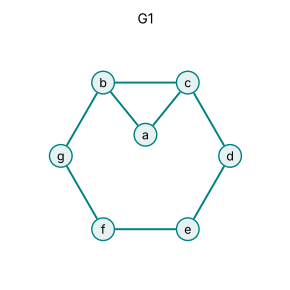

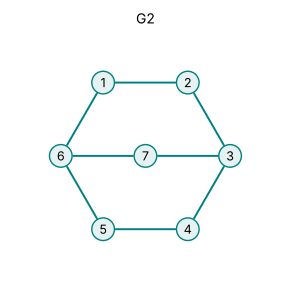

In [16]:
import math
hexa = lambda nombres: {v: (math.cos(math.pi * (2 - k) / 3), math.sin(math.pi * (2 - k) / 3))
                        for k, v in enumerate(nombres)}
p1 = hexa("bcdefg"); p1["a"] = (0, 0.25)
dibujar(p1, A1, titulo="G1")
p2 = hexa([1, 2, 3, 4, 5, 6]); p2[7] = (0, 0)
dibujar(p2, A2, titulo="G2");

Búsqueda de un isomorfismo por fuerza bruta (como mucho $n!$ biyecciones; sólo se prueban las que conservan los grados):

In [17]:
def isomorfismo(V1, A1, V2, A2):
    """
    Busca una biyección psi: V1 -> V2 que conserve las adyacencias
    (grafos simples). Devuelve un diccionario o None. Fuerza bruta: n!
    biyecciones como mucho, pero sólo se prueban las que conservan grados.
    """
    if len(V1) != len(V2) or len(A1) != len(A2):
        return None
    g1, g2 = grados(V1, A1), grados(V2, A2)
    if sorted(g1.values()) != sorted(g2.values()):
        return None
    E2 = {frozenset(a) for a in A2}
    for imagen in permutations(V2):
        psi = dict(zip(V1, imagen))
        if any(g1[x] != g2[psi[x]] for x in V1):
            continue
        if all(frozenset((psi[a], psi[b])) in E2 for a, b in A1):
            return psi
    return None

In [18]:
print("G1 y G4:", isomorfismo(V1, A1, V4, A4))
print("G1 y G2:", isomorfismo(V1, A1, V2, A2))
print("G1 y G3:", isomorfismo(V1, A1, V3, A3))

G1 y G4: {'a': 5, 'b': 1, 'c': 7, 'd': 3, 'e': 6, 'f': 2, 'g': 4}
G1 y G2: None
G1 y G3: None


- $G_3$ no es isomorfo a ninguno: no es conexo.
- $G_2$ no tiene triángulos y $G_1$ sí.
- $G_1$ y $G_4$ son isomorfos: el programa da la biyección.

### Los dos dibujos de $C_5$

In [19]:
P = list("abcde")
pent = [("a", "b"), ("b", "c"), ("c", "d"), ("d", "e"), ("e", "a")]
estrella = [("a", "c"), ("c", "e"), ("e", "b"), ("b", "d"), ("d", "a")]
print(isomorfismo(P, pent, P, estrella))

{'a': 'a', 'b': 'c', 'c': 'e', 'd': 'b', 'e': 'd'}


## 6. Grafos no etiquetados

La isomorfía es una relación de equivalencia; cada clase es un **grafo no etiquetado**. Para agrupar, asociamos a cada grafo su **forma canónica**: la menor lista de aristas entre todos sus reetiquetados. Dos grafos son isomorfos si y sólo si tienen la misma forma canónica.

In [20]:
def forma_canonica(vertices, aristas):
    """La menor lista de aristas entre todos los reetiquetados: igual para grafos isomorfos."""
    n = len(vertices)
    mejor = None
    for perm in permutations(range(n)):
        psi = dict(zip(vertices, perm))
        forma = tuple(sorted(tuple(sorted((psi[a], psi[b]))) for a, b in aristas))
        if mejor is None or forma < mejor:
            mejor = forma
    return mejor


def clases_de_isomorfia(vertices, lista_de_grafos):
    """Agrupa una lista de grafos (listas de aristas) en clases de isomorfía."""
    clases = {}
    for A in lista_de_grafos:
        clases.setdefault(forma_canonica(vertices, A), []).append(A)
    return list(clases.values())

In [21]:
V4 = ["x", "y", "z", "t"]
for m in range(7):
    G = grafos_simples(V4, m)
    C = clases_de_isomorfia(V4, G)
    print(f"{m} aristas: {len(G):>2} etiquetados, {len(C)} no etiquetados, tamaños {[len(cl) for cl in C]}")

0 aristas:  1 etiquetados, 1 no etiquetados, tamaños [1]
1 aristas:  6 etiquetados, 1 no etiquetados, tamaños [6]
2 aristas: 15 etiquetados, 2 no etiquetados, tamaños [12, 3]
3 aristas: 20 etiquetados, 3 no etiquetados, tamaños [4, 4, 12]
4 aristas: 15 etiquetados, 2 no etiquetados, tamaños [12, 3]
5 aristas:  6 etiquetados, 1 no etiquetados, tamaños [6]
6 aristas:  1 etiquetados, 1 no etiquetados, tamaños [1]


Con $2$ aristas: $15$ grafos etiquetados y $2$ no etiquetados (problema de las transparencias). Con $3$ aristas (problema 4.1): $20$ etiquetados y $3$ no etiquetados, la estrella ($4$), el triángulo con un vértice aislado ($4$) y el camino de longitud $3$ ($12$). En total hay $11$ grafos no etiquetados con $4$ vértices.

Dibujamos un representante de cada clase con $3$ aristas:

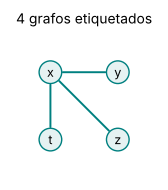

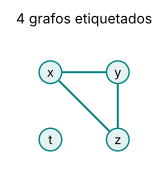

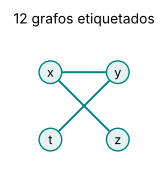

In [22]:
cuadrado = {"x": (0, 1), "y": (1, 1), "z": (1, 0), "t": (0, 0)}
for cl in clases_de_isomorfia(V4, grafos_simples(V4, 3)):
    dibujar(cuadrado, cl[0], titulo=f"{len(cl)} grafos etiquetados", tam=(2, 2))

## Referencias

- Grimaldi, R. P. (1998). *Matemática discreta y combinatoria* (3ª ed.). Addison Wesley Longman. Capítulo 11.
- Rosen, K. H. (2004). *Matemática discreta y sus aplicaciones* (5ª ed.). McGraw-Hill. Capítulo 8.